C:\Users\Harini.S\AppData\Local\Temp\ipykernel_5272\1428460050.py:5: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("archive/cleaned_amazon_sales.csv")


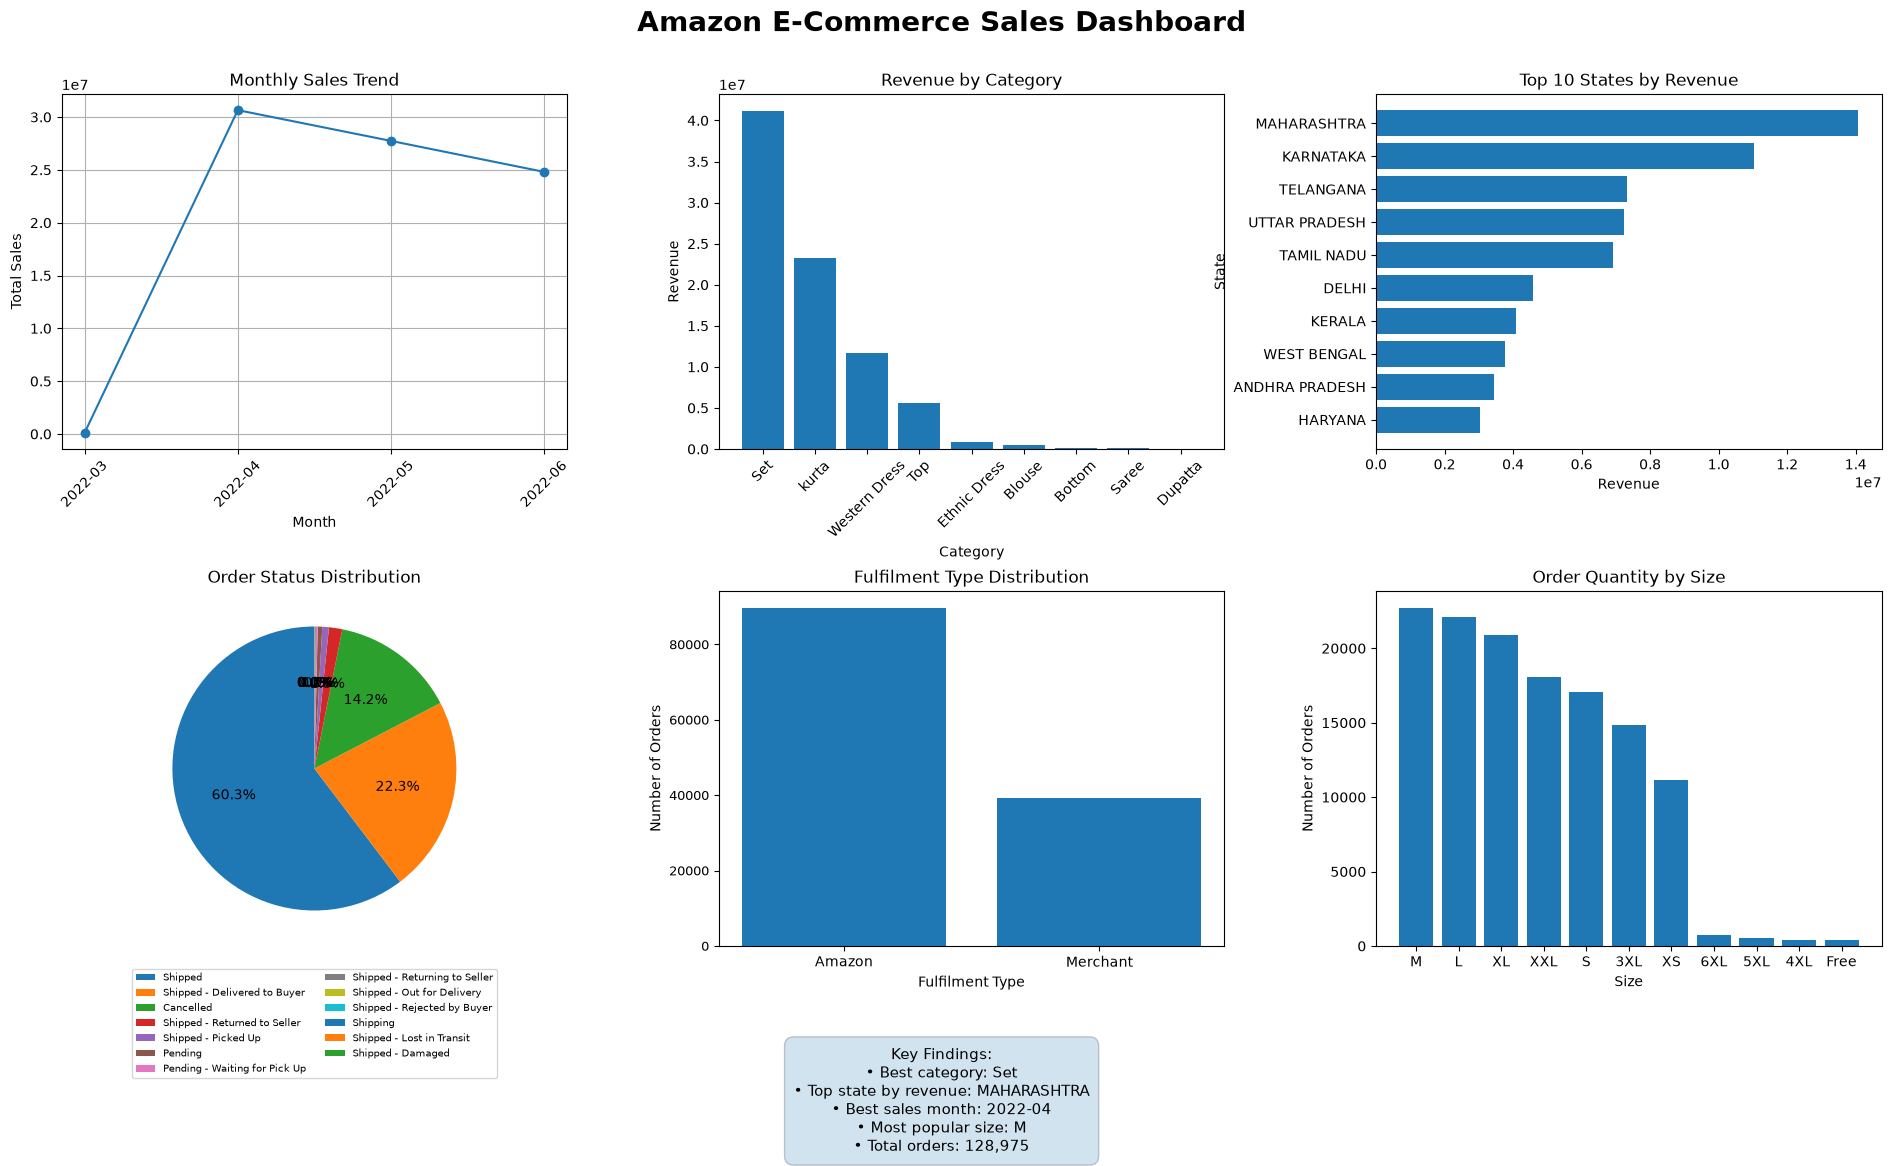

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("archive/cleaned_amazon_sales.csv")


# 1. Prepare data for dashboard

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Year_Month"] = df["Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Year_Month")["Amount"]
    .sum()
    .reset_index()
)

category_revenue = (
    df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

state_revenue = (
    df.groupby("ship-state")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

status_distribution = df["Status"].value_counts()

fulfilment_distribution = df["Fulfilment"].value_counts()

size_distribution = df["Size"].value_counts()

# 2. Create dashboard

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

fig.suptitle(
    "Amazon E-Commerce Sales Dashboard",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

axes[0, 0].plot(
    monthly_sales["Year_Month"].astype(str),
    monthly_sales["Amount"],
    marker="o"
)

axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True)

axes[0, 1].bar(
    category_revenue.index,
    category_revenue.values
)

axes[0, 1].set_title("Revenue by Category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Revenue")
axes[0, 1].tick_params(axis="x", rotation=45)

# Chart 3: Top 10 States by Revenue

axes[0, 2].barh(
    state_revenue.index,
    state_revenue.values
)

axes[0, 2].set_title("Top 10 States by Revenue")
axes[0, 2].set_xlabel("Revenue")
axes[0, 2].set_ylabel("State")

# Chart 4: Order Status Distribution

axes[1, 0].pie(
    status_distribution.values,
    autopct="%1.1f%%",
    startangle=90
)

axes[1, 0].set_title("Order Status Distribution")

axes[1, 0].legend(
    status_distribution.index,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    fontsize=7,
    ncol=2
)

# Chart 5: Fulfilment Type Distribution

axes[1, 1].bar(
    fulfilment_distribution.index,
    fulfilment_distribution.values
)

axes[1, 1].set_title("Fulfilment Type Distribution")
axes[1, 1].set_xlabel("Fulfilment Type")
axes[1, 1].set_ylabel("Number of Orders")

# Make y-axis label clearly visible
axes[1, 1].tick_params(axis="y", labelsize=9)

# Chart 6: Size Segmentation

axes[1, 2].bar(
    size_distribution.index,
    size_distribution.values
)

axes[1, 2].set_title("Order Quantity by Size")
axes[1, 2].set_xlabel("Size")
axes[1, 2].set_ylabel("Number of Orders")

axes[1, 2].tick_params(axis="x", rotation=0)

# 3. Summary text box

best_category = category_revenue.idxmax()

best_state = state_revenue.idxmax()

best_month = monthly_sales.loc[
    monthly_sales["Amount"].idxmax(),
    "Year_Month"
]

popular_size = size_distribution.idxmax()

summary = (
    f"Key Findings:\n"
    f"• Best category: {best_category}\n"
    f"• Top state by revenue: {best_state}\n"
    f"• Best sales month: {best_month}\n"
    f"• Most popular size: {popular_size}\n"
    f"• Total orders: {len(df):,}"
)

fig.text(
    0.5,
    0.025,
    summary,
    ha="center",
    va="bottom",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.6",
        alpha=0.2
    )
)

# 4. Adjust dashboard spacing

plt.subplots_adjust(
    left=0.06,
    right=0.97,
    top=0.91,
    bottom=0.20,
    hspace=0.40,
    wspace=0.30
)

# 5. Save dashboard

plt.savefig(
    "archive/ecommerce_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)


# Display dashboard
plt.show()